<h1>EDA Предсказание оттока подрядчиков</h1>
<h2>AI Challenge 2024

<h4>Importing libraries</h4>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')

<h4>Loading data</h4>

In [2]:
description = pd.read_excel('../data/description.xlsx')
description.head()

,колонка,описание
0,contract_id,Уникальный идентификатор контракта ...
1,report_date,Дата среза
2,specialization_id,Идентификатор специализации ...
3,contract_init_sum,Начальная сумма контракта ...
4,contract_date,Дата заключения контракта ...


In [3]:
X_train = pd.read_csv('../data/train_X.csv')
X_test = pd.read_csv('../data/test1_X.csv')
X_train.head()

,contract_id,report_date,specialization_id,contract_init_sum,contract_date,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
0,5433,2023-01-01,18,1.115267,2022-05-10 21:00:00,43,701,438,0.793952,-0.539030,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
1,6875,2023-01-01,18,1.608002,2022-08-21 21:00:00,31,268,438,2.681675,0.743673,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
2,1476,2023-01-01,18,-0.360764,2022-10-17 21:00:00,31,268,438,-0.416432,-0.539030,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
3,4469,2023-01-01,12,-0.089303,2022-04-20 21:00:00,43,697,484,-0.193827,-0.539030,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
4,1330,2023-01-01,12,-0.515778,2022-03-02 21:00:00,49,224,484,0.133446,0.743673,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454


In [4]:
y_train = pd.read_csv('../data/train_y.csv')
y_train.head()

,contract_id,report_date,default6
0,5433,2023-01-01,0
1,6875,2023-01-01,0
2,1476,2023-01-01,0
3,4469,2023-01-01,0
4,1330,2023-01-01,0


<h4>General info</h4>

In [5]:
print('Train shape: ', X_train.shape)
print('Test shape: ', X_test.shape)
print('Description shape: ', description.shape)

Train shape:  (28831, 169)
Test shape:  (7332, 169)
Description shape:  (170, 2)


In [6]:
X_train.isna().sum().sort_values(ascending=False)

agg_FinanceAndTaxesFTS__g_contractor__TaxPenaltiesSum__last__ALL_TIME              25425
agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__mean__ALL_TIME    23736
agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__last__ALL_TIME    23736
agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__last__ALL_TIME    21507
agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__mean__ALL_TIME    21507
                                                                                   ...  
counteragent_mean_agg_payments__g_contract__sum__all__sum__ALL_TIME                    0
counteragent_sum_agg_payments__g_contract__sum__all__sum__ALL_TIME                     0
specialization_sum_agg_payments__g_contract__sum__all__sum__ALL_TIME                   0
agg_payments__g_contract__date__advance__min__ALL_TIME                                 0
agg_spass_applications__g_contract__appl_count_week__mean__5W                          0
Length: 169, dtype: i

In [7]:
X_train.isna().sum().mean()

2376.6923076923076

In [8]:
X_train.isnull().any()

contract_id                                                            False
report_date                                                            False
specialization_id                                                      False
contract_init_sum                                                      False
contract_date                                                          False
                                                                       ...  
agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W           True
agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W          True
agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W          True
agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W          True
agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME     True
Length: 169, dtype: bool

In [9]:
X_train.isnull().any().sum()

62

In [10]:
X_test.isna().sum().sort_values(ascending=False)

agg_FinanceAndTaxesFTS__g_contractor__TaxPenaltiesSum__last__ALL_TIME              6856
agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__mean__ALL_TIME    6671
agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__last__ALL_TIME    6671
agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__last__ALL_TIME    6153
agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__mean__ALL_TIME    6153
                                                                                   ... 
counteragent_mean_agg_payments__g_contract__sum__all__sum__ALL_TIME                   0
counteragent_sum_agg_payments__g_contract__sum__all__sum__ALL_TIME                    0
specialization_sum_agg_payments__g_contract__sum__all__sum__ALL_TIME                  0
agg_payments__g_contract__date__advance__min__ALL_TIME                                0
agg_spass_applications__g_contract__appl_count_week__mean__5W                         0
Length: 169, dtype: int64

In [11]:
X_test.isnull().any().sum()

62

In [12]:
X_train.describe()

,contract_id,specialization_id,contract_init_sum,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__last__ALL_TIME,agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__mean__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
count,28831.000000,28831.000000,28831.000000,28831.000000,28831.000000,28831.000000,28831.000000,28831.000000,7324.000000,7324.000000,...,22778.000000,22778.000000,24803.000000,24803.000000,24803.000000,24803.000000,24803.000000,24803.000000,24803.000000,24803.000000
mean,3554.436336,14.395928,-0.001099,30.313413,629.534425,467.119455,0.010249,-0.101690,0.127710,0.136740,...,-0.019310,-0.019311,-0.023482,-0.024440,-0.024860,-0.024207,-0.036779,-0.085798,-0.109415,-0.111126
std,2097.700813,6.917339,0.970751,16.044933,304.176817,255.487449,0.981958,0.859366,1.118366,1.143575,...,0.938552,0.938545,0.868912,0.882314,0.927216,0.992106,0.926070,0.655029,0.625597,0.624505
min,2.000000,0.000000,-0.515778,0.000000,1.000000,2.000000,-0.543405,-0.539030,-1.325012,-1.131978,...,-0.158471,-0.158474,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
25%,1716.000000,9.000000,-0.484227,17.000000,344.000000,249.000000,-0.483060,-0.539030,-0.389711,-0.416847,...,-0.158471,-0.158474,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
50%,3537.000000,14.000000,-0.356204,31.000000,711.000000,468.000000,-0.360093,-0.539030,-0.314321,-0.321923,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
75%,5298.000000,20.000000,0.034759,45.000000,915.000000,683.000000,0.056818,0.743673,0.089142,0.206397,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
max,7341.000000,31.000000,11.303436,56.000000,915.000000,898.000000,11.571101,7.157189,12.218540,12.762946,...,6.312293,6.310387,24.941455,21.386181,16.393783,15.338671,13.509656,9.128242,8.336741,8.320025


In [13]:
X_test.describe()

,contract_id,specialization_id,contract_init_sum,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__last__ALL_TIME,agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__mean__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
count,7332.000000,7332.000000,7332.000000,7332.000000,7332.00000,7332.000000,7332.000000,7332.000000,1179.000000,1179.000000,...,5620.000000,5620.000000,6752.000000,6752.000000,6752.000000,6752.000000,6752.000000,6752.000000,6752.000000,6752.000000
mean,3754.843153,14.977496,-0.041822,30.268822,523.65862,471.994544,-0.062638,-0.286408,0.261077,0.282421,...,0.007281,0.007281,-0.048023,-0.068085,-0.091312,-0.085272,-0.048599,-0.006434,-0.004266,-0.005081
std,2150.879809,7.035030,0.933305,15.757078,298.62296,258.732916,0.852689,0.644643,1.153429,1.218482,...,1.022214,1.022216,0.617109,0.502188,0.386537,0.457762,0.740263,1.029532,1.005750,1.005952
min,4.000000,0.000000,-0.515778,0.000000,2.00000,0.000000,-0.543410,-0.539030,-0.632865,-0.681374,...,-0.158471,-0.158474,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
25%,1927.000000,10.000000,-0.491381,18.000000,251.00000,246.000000,-0.504333,-0.539030,-0.352939,-0.386211,...,-0.158471,-0.158474,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
50%,3804.000000,14.000000,-0.395055,30.000000,531.00000,481.000000,-0.395517,-0.539030,-0.194211,-0.197518,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
75%,5641.000000,21.000000,-0.081384,45.000000,815.00000,713.000000,-0.037228,-0.539030,0.348679,0.480381,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.238986,-0.240767
max,7338.000000,31.000000,7.602531,56.000000,915.00000,896.000000,6.909000,4.591783,10.026584,10.469861,...,6.310370,6.310387,16.320773,14.848690,8.405312,6.001834,10.686007,9.243961,8.691110,8.673776


In [14]:
for i in range(description.shape[0]):
    row = description.iloc[i, :] 
    print(row['колонка'])

contract_id
report_date
specialization_id
contract_init_sum
contract_date
project_id
building_id
contractor_id
contract_current_sum
agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME
agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__last__ALL_TIME
agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__mean__ALL_TIME
agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__last__ALL_TIME
agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__mean__ALL_TIME
agg_cec_requests__g_contract__request_id__all__count__1W
agg_cec_requests__g_contract__request_id__all__count__2W
agg_cec_requests__g_contract__request_id__all__count__3W
agg_cec_requests__g_contract__request_id__all__count__4W
agg_cec_requests__g_contract__request_id__all__count__5W
agg_cec_requests__g_contract__request_id__all__count__6W
agg_cec_requests__g_contract__request_id__all__count__7W
agg_cec_requests__g_contract__request_id__all__count__8W
agg_cec_requests__g_cont

In [15]:
for i in range(description.shape[0]):
    row = description.iloc[i, :] 
    print(row['колонка'], '\t\t', row['описание'])

contract_id 		  Уникальный идентификатор контракта                                                                     
report_date 		  Дата среза 
specialization_id 		  Идентификатор специализации                                                                            
contract_init_sum 		  Начальная сумма контракта                                                                              
contract_date 		  Дата заключения контракта                                                                              
project_id 		  Идентификатор проекта                                                                                  
building_id 		  Идентификатор здания                                                                                   
contractor_id 		  Идентификатор подрядчика                                                                               
contract_current_sum 		  Текущая сумма контракта                                                                     

In [16]:
X_train['report_date'] = pd.to_datetime(X_train['report_date'])
X_test['report_date'] = pd.to_datetime(X_test['report_date'])
X_train['contract_date'] = pd.to_datetime(X_train['contract_date'])
X_test['contract_date'] = pd.to_datetime(X_test['contract_date'])

In [17]:
print('Min report date (X train):', X_train['report_date'].min().strftime('%Y-%m-%d'), ' | Max report date (X train):', X_train['report_date'].max().strftime('%Y-%m-%d'))
print('Min report date (X test):', X_test['report_date'].min().strftime('%Y-%m-%d'), ' | Max report date (X test):', X_test['report_date'].max().strftime('%Y-%m-%d'))

Min report date (X train): 2023-01-01  | Max report date (X train): 2023-07-23
Min report date (X test): 2023-07-30  | Max report date (X test): 2023-09-24


In [18]:
print('Min contract date (X train):', X_train['contract_date'].min().strftime('%Y-%m-%d'), ' | Max contract date (X train):', X_train['contract_date'].max().strftime('%Y-%m-%d'))
print('Min contract date (X test):', X_test['contract_date'].min().strftime('%Y-%m-%d'), ' | Max contract date (X test):', X_test['contract_date'].max().strftime('%Y-%m-%d'))

Min contract date (X train): 2022-01-09  | Max contract date (X train): 2023-07-22
Min contract date (X test): 2022-01-16  | Max contract date (X test): 2023-09-21


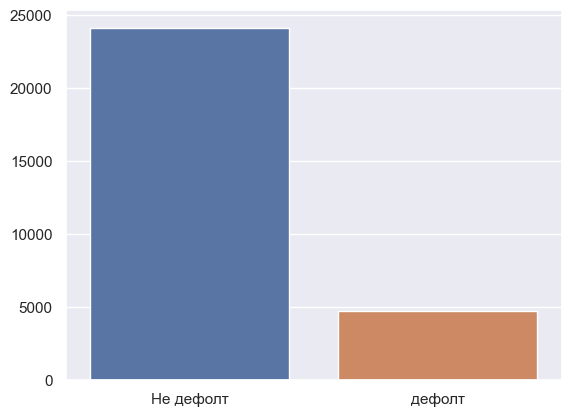

In [19]:
sns.barplot(x=['Не дефолт', 'дефолт'], y=y_train['default6'].value_counts().values);

In [20]:
X_train['contractor_id'].nunique() 

646

In [21]:
X_train.groupby('contractor_id')['contract_id'].nunique().mean()

5.337461300309598

In [22]:
X_train.groupby('contractor_id')['contract_id'].count().mean()

44.630030959752325

In [23]:
X_train.sample(1)

,contract_id,report_date,specialization_id,contract_init_sum,contract_date,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
23110,6526,2023-06-18,6,-0.400859,2023-04-21 21:00:00,21,495,659,-0.44931,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454


In [24]:
X_train[X_train['contractor_id'] == 216]

,contract_id,report_date,specialization_id,contract_init_sum,contract_date,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
17633,1861,2023-05-07,15,1.833254,2023-05-01 21:00:00,36,915,216,1.38272,-0.53903,...,-0.158471,-0.158474,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454


In [25]:
X_test['contract_id'].value_counts()

contract_id
3029    9
6476    9
5059    9
878     9
4595    9
       ..
2640    1
1273    1
5225    1
3957    1
1181    1
Name: count, Length: 1610, dtype: int64

In [26]:
y_train.contract_id.value_counts()

contract_id
5533    30
1906    30
576     30
5927    30
2918    30
        ..
138      1
5809     1
1069     1
5007     1
5351     1
Name: count, Length: 3448, dtype: int64

In [27]:
X_test['contract_id'].value_counts()

contract_id
3029    9
6476    9
5059    9
878     9
4595    9
       ..
2640    1
1273    1
5225    1
3957    1
1181    1
Name: count, Length: 1610, dtype: int64

In [28]:
X_test[X_test['contract_id'] == 3029]

,contract_id,report_date,specialization_id,contract_init_sum,contract_date,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
0,3029,2023-07-30,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
689,3029,2023-08-06,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
1183,3029,2023-08-13,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
2319,3029,2023-08-20,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
3278,3029,2023-08-27,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
4122,3029,2023-09-03,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
5195,3029,2023-09-10,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
5437,3029,2023-09-17,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
6655,3029,2023-09-24,15,-0.347029,2023-07-24 21:00:00,42,84,637,-0.405169,-0.53903,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454


In [29]:
X_test.groupby('report_date')['contract_id'].count()

report_date
2023-07-30     512
2023-08-06     614
2023-08-13     668
2023-08-20     708
2023-08-27     847
2023-09-03     926
2023-09-10     966
2023-09-17    1036
2023-09-24    1055
Name: contract_id, dtype: int64

In [30]:
X_train.groupby('report_date')['contract_id'].count().sort_index()

report_date
2023-01-01    1346
2023-01-08    1251
2023-01-15    1209
2023-01-22    1127
2023-01-29    1061
2023-02-05     990
2023-02-12     944
2023-02-19     884
2023-02-26     880
2023-03-05     839
2023-03-12     831
2023-03-19     838
2023-03-26     837
2023-04-02     855
2023-04-09     851
2023-04-16     819
2023-04-23     851
2023-04-30     853
2023-05-07     879
2023-05-14     855
2023-05-21     873
2023-05-28     903
2023-06-04     921
2023-06-11     948
2023-06-18     969
2023-06-25     989
2023-07-02    1052
2023-07-09    1038
2023-07-16    1047
2023-07-23    1091
Name: contract_id, dtype: int64

In [31]:
train_nans = X_train.isna().sum().sort_values(ascending=False)
for col, nans in zip(train_nans.index, train_nans.values):
    if nans != 0:
        print(col, '\t', nans)
        print(description[description['колонка']==col]['описание'].values[0])
        print("\n")

agg_FinanceAndTaxesFTS__g_contractor__TaxPenaltiesSum__last__ALL_TIME 	 25425
 Сумма налоговых штрафов                          


agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__mean__ALL_TIME 	 23736
 Среднее относительное изменение цены контракта за все время                                            


agg_all_contracts__g_contract__rel_change_price_last_ds__isMain__last__ALL_TIME 	 23736
 Последнее относительное изменение цены контракта за все время                                          


agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__last__ALL_TIME 	 21507
 Последнее абсолютное изменение цены контракта за все время                                             


agg_all_contracts__g_contract__abs_change_price_last_ds__isMain__mean__ALL_TIME 	 21507
 Среднее абсолютное изменение цены контракта за все время                                               


agg_FinanceAndTaxesFTS__g_contractor__TaxArrearsSum__last__ALL_TIME 	 18993
 Сумма налого

In [32]:
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

In [33]:
X_train.isna().sum()

contract_id                                                            0
report_date                                                            0
specialization_id                                                      0
contract_init_sum                                                      0
contract_date                                                          0
                                                                      ..
agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W          0
agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W         0
agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W         0
agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W         0
agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME    0
Length: 169, dtype: int64

In [34]:
X_train['contract_current_sum'].var()

0.9642412534533634

In [35]:
X_train['contract_current_sum'].mean()

0.010248617569621903

In [36]:
X_train['contract_init_sum'].mean()

-0.0010991630749026496

In [37]:
X_train['contract_init_sum'].var()

0.9423567923964116

In [38]:
X_train['contract_init_sum'].mean()

-0.0010991630749026496

In [39]:
X_train.groupby('contract_id')['report_date'].count().mean()

8.361658932714617

In [40]:
X_train.head()

,contract_id,report_date,specialization_id,contract_init_sum,contract_date,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
0,5433,2023-01-01,18,1.115267,2022-05-10 21:00:00,43,701,438,0.793952,-0.539030,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
1,6875,2023-01-01,18,1.608002,2022-08-21 21:00:00,31,268,438,2.681675,0.743673,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
2,1476,2023-01-01,18,-0.360764,2022-10-17 21:00:00,31,268,438,-0.416432,-0.539030,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
3,4469,2023-01-01,12,-0.089303,2022-04-20 21:00:00,43,697,484,-0.193827,-0.539030,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
4,1330,2023-01-01,12,-0.515778,2022-03-02 21:00:00,49,224,484,0.133446,0.743673,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454


In [41]:
print('Кол-во IDишников подрядчиков из трейна в тесте:', pd.Series(X_test['contractor_id'].unique()).isin(X_train['contractor_id'].unique()).sum(), '\n'
      'Доля ID из трейна, которые есть в тесте:', round(pd.Series(X_test['contractor_id'].unique()).isin(X_train['contractor_id'].unique()).sum() / X_train['contractor_id'].nunique(), 3))

Кол-во IDишников подрядчиков из трейна в тесте: 356 
Доля ID из трейна, которые есть в тесте: 0.551


In [42]:
print('Кол-во IDишников проектов из трейна в тесте:', pd.Series(X_test['project_id'].unique()).isin(X_train['project_id'].unique()).sum(), '\n'
      'Доля ID из трейна, которые есть в тесте:', round(pd.Series(X_test['project_id'].unique()).isin(X_train['project_id'].unique()).sum() / X_train['project_id'].nunique(), 3))

Кол-во IDишников проектов из трейна в тесте: 47 
Доля ID из трейна, которые есть в тесте: 0.94


In [43]:
print('Кол-во IDишников специализаций из трейна в тесте:', pd.Series(X_test['specialization_id'].unique()).isin(X_train['specialization_id'].unique()).sum(), '\n'
      'Доля ID из трейна, которые есть в тесте:', round(pd.Series(X_test['specialization_id'].unique()).isin(X_train['specialization_id'].unique()).sum() / X_train['specialization_id'].nunique(), 3))

Кол-во IDишников специализаций из трейна в тесте: 28 
Доля ID из трейна, которые есть в тесте: 0.903


In [44]:
print('Кол-во IDишников здания/сооружения из трейна в тесте:', pd.Series(X_test['building_id'].unique()).isin(X_train['building_id'].unique()).sum(), '\n'
      'Доля ID из трейна, которые есть в тесте:', round(pd.Series(X_test['building_id'].unique()).isin(X_train['building_id'].unique()).sum() / X_train['building_id'].nunique(), 3))

Кол-во IDишников здания/сооружения из трейна в тесте: 328 
Доля ID из трейна, которые есть в тесте: 0.551


In [45]:
print('Кол-во IDишников контрактов из трейна в тесте:', pd.Series(X_test['contract_id'].unique()).isin(X_train['contract_id'].unique()).sum(), '\n'
      'Доля ID из трейна, которые есть в тесте:', round(pd.Series(X_test['contract_id'].unique()).isin(X_train['contract_id'].unique()).sum() / X_train['contract_id'].nunique(), 3))

Кол-во IDишников контрактов из трейна в тесте: 0 
Доля ID из трейна, которые есть в тесте: 0.0


In [46]:
def process_df(dataframe: pd.DataFrame):
    df = dataframe.copy()
    df = df.sort_values(by='report_date')
    df = df.drop(['report_date', 'project_id'])

In [47]:
X_train_by_contract = []
for name, group in X_train.groupby('contract_id'):
    X_train_by_contract.append(group.values)
    


In [53]:
X_train.head()

,contract_id,report_date,specialization_id,contract_init_sum,contract_date,project_id,building_id,contractor_id,contract_current_sum,agg_all_contracts__g_contract__bit_da_guid__isMain__count__ALL_TIME,...,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__12_48M,agg_ArbitrationCases__g_contractor__PlaintiffSum__sum__ALL_TIME,agg_tender_proposal__g_contractor__id__ALL__countDistinct__1W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__2W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__4W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__8W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__12W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__26W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__52W,agg_tender_proposal__g_contractor__id__ALL__countDistinct__ALL_TIME
0,5433,2023-01-01,18,1.115267,2022-05-10 21:00:00,43,701,438,0.793952,-0.539030,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
1,6875,2023-01-01,18,1.608002,2022-08-21 21:00:00,31,268,438,2.681675,0.743673,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
2,1476,2023-01-01,18,-0.360764,2022-10-17 21:00:00,31,268,438,-0.416432,-0.539030,...,-0.158471,-0.158473,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
3,4469,2023-01-01,12,-0.089303,2022-04-20 21:00:00,43,697,484,-0.193827,-0.539030,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454
4,1330,2023-01-01,12,-0.515778,2022-03-02 21:00:00,49,224,484,0.133446,0.743673,...,-0.158470,-0.158471,-0.136894,-0.157822,-0.178045,-0.190966,-0.200348,-0.225724,-0.256704,-0.258454


In [86]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
X_train_pca = X_train.drop(['contract_id', 'report_date', 'contract_date', 'specialization_id', 'project_id', 'building_id', 'contractor_id'], axis=1)
X_train_processed = StandardScaler().fit_transform(X_train[['specialization_id', 'project_id', 'building_id', 'contractor_id']])
X_train_processed = np.concatenate([X_train_pca.values, X_train_processed], axis=1)
print(X_train_processed.shape)
pca = PCA().fit(X_train_processed)

(28831, 166)


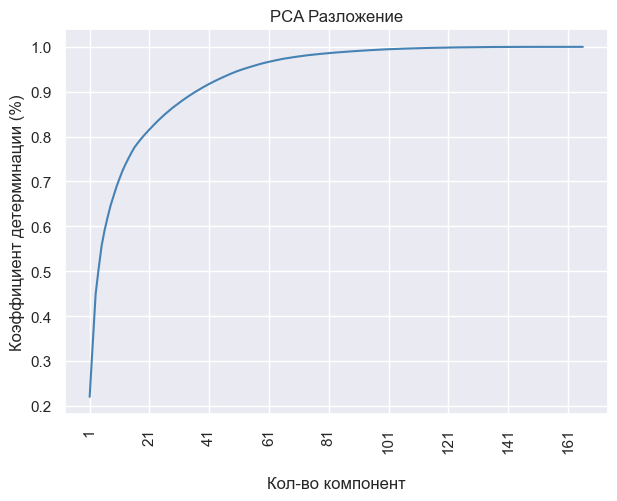

In [87]:
plt.figure(figsize = (7, 5))
ax = sns.lineplot(x = [i for i in range(1, 167)], y = np.cumsum(pca.explained_variance_ratio_), color = 'steelblue', markers = True);
ax.set_xlabel('\nКол-во компонент')
plt.xticks(rotation=90)
ax.set_ylabel('Коэффициент детерминации (%)')
ax.set_xticks([i for i in range(1, 167, 20)])
plt.xticks(fontsize=11);
plt.title('PCA Разложение');

In [58]:
pca.explained_variance_ratio_.shape

(166,)

In [61]:
np.cumsum(pca.explained_variance_ratio_).shape

(166,)